# 05 — Emerging-Threat Detection with BERTopic

**Inputs:** `artifacts/train.csv`, `artifacts/train_emb.npy`  
**Outputs:**
- `artifacts/bertopic_model/`
- `artifacts/rel_with_topics.csv`
- `artifacts/topic_info.csv`
- `artifacts/metrics_bertopic.json`
- `artifacts/figs/fig_topic_sizes.png`
- `artifacts/figs/fig_topic_barchart.html`
- `artifacts/figs/fig_topic_heatmap.html`
- *(optional)* `artifacts/topic_prevalence_by_quarter.csv` and `fig_topic_prevalence.png`

**Feeds thesis:** Chapter 4.3 (topic discovery) and Chapter 4.4 (temporal, optional)

### Methodology note

BERTopic is applied to the **relevant sentences only** (label=1) from the training
set — mixing irrelevant sentences would pollute the topic space. Evaluation uses
c_v coherence and topic diversity.

The temporal-analysis cell is **optional** and only runs if `artifacts/doc_dates.csv`
exists. The cell is **robust** to either a `document_id` or `doc_id` column in the
dates file (the raw SMAH-CTI schema used `doc_id`; preprocessing renamed it to
`document_id`). If the dates file has zero overlap with the relevant subset, the
cell reports this explicitly instead of producing a blank plot.

## 1. Setup

In [1]:
import pandas as pd, numpy as np, json, os
import matplotlib.pyplot as plt
import seaborn as sns
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

os.makedirs('../artifacts/figs', exist_ok=True)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

train = pd.read_csv('../artifacts/train.csv')
rel = train[train['relevant'] == 1].reset_index(drop=True)
print('relevant sentences:', len(rel))
print('documents in relevant subset:', rel['document_id'].nunique())

c:\Users\Hp\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



relevant sentences: 3107
documents in relevant subset: 77


## 2. Reuse cached SBERT embeddings

Notebook 4 already computed `train_emb.npy`. Reuse those rows for the relevant subset.

In [2]:
EMB_TRAIN = '../artifacts/train_emb.npy'

if os.path.exists(EMB_TRAIN):
    all_emb = np.load(EMB_TRAIN)
    emb = all_emb[train['relevant'].values == 1]
    print('reused embeddings:', emb.shape)
else:
    sbert = SentenceTransformer('all-MiniLM-L6-v2')
    emb = sbert.encode(rel['sentence_text'].tolist(), batch_size=64,
                       show_progress_bar=True, convert_to_numpy=True)
    print('recomputed embeddings:', emb.shape)

assert len(emb) == len(rel), 'Embedding / row mismatch'

reused embeddings: (3107, 384)


## 3. Fit BERTopic

Pipeline: SBERT embeddings → UMAP (5-d) → HDBSCAN (min_cluster_size=20) → c-TF-IDF.

In [3]:
umap_model    = UMAP(n_neighbors=15, n_components=5, metric='cosine', random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=20, metric='euclidean',
                        prediction_data=True)

topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    calculate_probabilities=False,
    verbose=True,
)

topics, probs = topic_model.fit_transform(rel['sentence_text'].tolist(), emb)
info = topic_model.get_topic_info()
print(info.head(25).to_string(index=False))

2026-10-19 14:49:24,037 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-19 14:50:12,429 - BERTopic - Dimensionality - Completed ✓
2026-10-19 14:50:12,436 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-19 14:50:12,725 - BERTopic - Cluster - Completed ✓
2026-10-19 14:50:12,743 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-19 14:50:12,963 - BERTopic - Representation - Completed ✓


 Topic  Count                                         Name                                                                                                                           Representation                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

## 4. Save model & topic assignments

In [4]:
topic_model.save('../artifacts/bertopic_model', serialization='safetensors')
rel_out = rel.copy()
rel_out['topic'] = topics
rel_out.to_csv('../artifacts/rel_with_topics.csv', index=False)
info.to_csv('../artifacts/topic_info.csv', index=False)
print('saved model + rel_with_topics.csv + topic_info.csv')

saved model + rel_with_topics.csv + topic_info.csv


## 5. Top-10 words per topic

In [5]:
def print_topics(topic_model, n_topics=15, top_n=10):
    for tid in topic_model.get_topics():
        if tid == -1: continue
        words = [w for w, _ in topic_model.get_topic(tid)][:top_n]
        size = int(topic_model.get_topic_info().set_index('Topic').loc[tid, 'Count'])
        print(f'Topic {tid:>3d} (size={size:>4d}): ' + ', '.join(words))
        if tid >= n_topics: break

print_topics(topic_model, n_topics=15)

Topic   0 (size= 188): file, the, dll, is, named, contains, gopher, arid, and, to
Topic   1 (size= 161): phishing, to, email, emails, of, and, as, they, in, the
Topic   2 (size= 120): c2, the, server, socket, from, communication, malware, to, it, cc
Topic   3 (size= 119): zeroday, exploitation, in, vulnerabilities, vulnerability, exploited, exploit, 2024, threat, of
Topic   4 (size= 108): credentials, access, cloud, to, adversaries, and, accounts, valid, the, for
Topic   5 (size= 104): north, cyber, korean, korea, dprk, koreas, it, of, and, 2025
Topic   6 (size= 102): ransomware, cybervolk, ransom, the, and, in, hexalocker, dragonforce, of, to
Topic   7 (size=  79): data, the, is, key, payload, then, base64, executed, and, decryption
Topic   8 (size=  54): fortimanager, fortigate, fortianalyzer, actor, devices, threat, the, seen, to, tableflip
Topic   9 (size=  53): spider, scattered, curly, azure, to, victim, in, alpha, spiders, 2023
Topic  10 (size=  53): the, system, file, initrd, e

## 6. Topic coherence (c_v)

Higher is better. Above ~0.5 = meaningful topics; below ~0.3 = noise.

In [6]:
def topic_coherence(topic_model, docs, top_n=10):
    topics_words = []
    for tid in topic_model.get_topics():
        if tid == -1: continue
        topics_words.append([w for w, _ in topic_model.get_topic(tid)][:top_n])
    tokenized = [d.split() for d in docs]
    dic = Dictionary(tokenized)
    cm = CoherenceModel(topics=topics_words, texts=tokenized,
                        dictionary=dic, coherence='c_v')
    return cm.get_coherence()

coh = topic_coherence(topic_model, rel['sentence_text'].tolist())
print('c_v coherence:', round(coh, 4))

c_v coherence: 0.4659


## 7. Topic diversity

In [7]:
def topic_diversity(topic_model, top_n=10):
    words = []
    for tid in topic_model.get_topics():
        if tid == -1: continue
        words += [w for w, _ in topic_model.get_topic(tid)][:top_n]
    return len(set(words)) / max(len(words), 1)

div = topic_diversity(topic_model)
print('topic diversity:', round(div, 4))

topic diversity: 0.7917


## 8. Save BERTopic metrics

In [8]:
metrics_bt = {
    'n_topics': int(len(info) - 1),
    'n_outliers': int((np.array(topics) == -1).sum()),
    'coherence_cv': round(float(coh), 4),
    'diversity':    round(float(div), 4),
    'min_cluster_size': 20,
}
json.dump(metrics_bt, open('../artifacts/metrics_bertopic.json','w'), indent=2)
print(json.dumps(metrics_bt, indent=2))

{
  "n_topics": 24,
  "n_outliers": 1594,
  "coherence_cv": 0.4659,
  "diversity": 0.7917,
  "min_cluster_size": 20
}


## 9. Topic barchart (interactive HTML)

In [9]:
try:
    fig = topic_model.visualize_barchart(top_n_topics=10, n_words=8)
    fig.write_html('../artifacts/figs/fig_topic_barchart.html')
    print('saved -> artifacts/figs/fig_topic_barchart.html')
except Exception as e:
    print('barchart skip:', e)

saved -> artifacts/figs/fig_topic_barchart.html


## 10. Topic similarity heatmap (interactive HTML)

In [10]:
try:
    fig = topic_model.visualize_heatmap(top_n_topics=15)
    fig.write_html('../artifacts/figs/fig_topic_heatmap.html')
    print('saved -> artifacts/figs/fig_topic_heatmap.html')
except Exception as e:
    print('heatmap skip:', e)

saved -> artifacts/figs/fig_topic_heatmap.html


## 11. Topic-size distribution

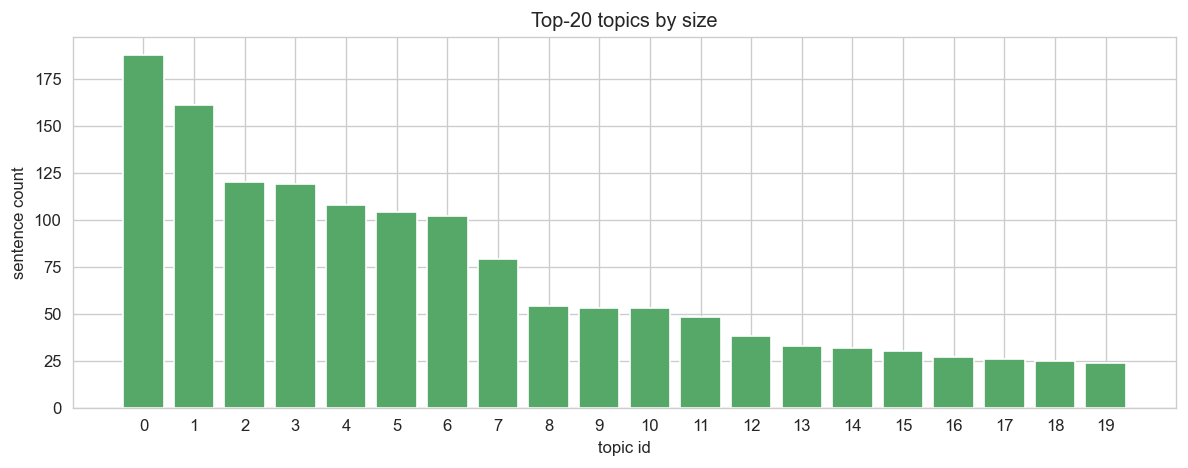

saved -> artifacts/figs/fig_topic_sizes.png


In [11]:
sizes = info[info['Topic'] != -1][['Topic','Count']].sort_values('Count', ascending=False).head(20)
plt.figure(figsize=(10, 4))
plt.bar(sizes['Topic'].astype(str), sizes['Count'], color='#55a868')
plt.xlabel('topic id'); plt.ylabel('sentence count')
plt.title('Top-20 topics by size')
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_topic_sizes.png')
plt.show()
print('saved -> artifacts/figs/fig_topic_sizes.png')

## 12. Optional — temporal analysis (FIXED)

**This cell is robust to both `document_id` and `doc_id`** in `doc_dates.csv`:

- If the file is missing → clean skip message.
- If the file has `doc_id` → column is renamed to `document_id` before merge.
- If the file has `document_id` → used directly.
- If both exist → `document_id` wins.
- If the merged set is empty → a diagnostic is printed with sample IDs from both
  tables, and the plot is skipped (no silent blank figure).
- If dates don't parse → rows are dropped with a warning count.

In [12]:
dates_path = '../artifacts/doc_dates.csv'

if not os.path.exists(dates_path):
    print('SKIP — no doc_dates.csv. Create one to enable temporal analysis.')
    print('Format (either column name accepted):')
    print('  document_id,date    OR    doc_id,date')
    print('  Example: 01_aptnotes_report,2015-03-15')
else:
    dates = pd.read_csv(dates_path)
    print(f'Loaded dates: {len(dates)} rows, columns={list(dates.columns)}')

    # ── Normalize the join key to `document_id` ─────────────
    if 'document_id' in dates.columns and 'doc_id' in dates.columns:
        dates = dates.drop(columns=['doc_id'])
    elif 'doc_id' in dates.columns and 'document_id' not in dates.columns:
        dates = dates.rename(columns={'doc_id': 'document_id'})
    elif 'document_id' not in dates.columns:
        raise KeyError(
            f"doc_dates.csv must contain either 'document_id' or 'doc_id'. "
            f"Found: {list(dates.columns)}"
        )

    # ── Validate date column ────────────────────────────────
    if 'date' not in dates.columns:
        raise KeyError(
            f"doc_dates.csv must contain a 'date' column. "
            f"Found: {list(dates.columns)}"
        )
    dates['date'] = pd.to_datetime(dates['date'], errors='coerce')
    n_before = len(dates)
    dates = dates.dropna(subset=['date'])
    if len(dates) < n_before:
        print(f'  dropped {n_before - len(dates)} rows with unparseable dates')

    # ── Merge on document_id ────────────────────────────────
    rel_t = rel_out.merge(dates[['document_id','date']],
                          on='document_id', how='inner')
    n_matched = rel_t['document_id'].nunique()
    print(f'Matched: {n_matched} documents ({len(rel_t)} relevant sentences with dates).')

    if n_matched == 0:
        print('⚠  NO OVERLAP between doc_dates.csv and the relevant subset.')
        print('   Sample document_id from rel_out:')
        print('  ', sorted(rel_out['document_id'].unique())[:5])
        print('   Sample document_id from dates:')
        print('  ', sorted(dates['document_id'].unique())[:5])
        print('   Temporal analysis skipped.')
    else:
        rel_t['quarter'] = rel_t['date'].dt.to_period('Q')
        prev = rel_t.groupby(['quarter','topic']).size().unstack(fill_value=0)
        prev_norm = prev.div(prev.sum(axis=1), axis=0)
        prev_norm.to_csv('../artifacts/topic_prevalence_by_quarter.csv')

        plt.figure(figsize=(11, 5))
        for tid in prev_norm.columns:
            if tid == -1: continue
            plt.plot(prev_norm.index.astype(str), prev_norm[tid],
                     marker='o', label=f'T{tid}')
        plt.title(f'Topic prevalence by quarter ({n_matched} documents)')
        plt.ylabel('share of relevant sentences')
        plt.xlabel('quarter')
        plt.xticks(rotation=45)
        plt.legend(ncol=4, fontsize=8)
        plt.tight_layout()
        plt.savefig('../artifacts/figs/fig_topic_prevalence.png')
        plt.show()
        print('saved -> artifacts/topic_prevalence_by_quarter.csv')
        print('saved -> artifacts/figs/fig_topic_prevalence.png')

Loaded dates: 0 rows, columns=['document_id', 'date']
Matched: 0 documents (0 relevant sentences with dates).
⚠  NO OVERLAP between doc_dates.csv and the relevant subset.
   Sample document_id from rel_out:
   ['02_aptnotes_report', '03_aptnotes_report', '04_aptnotes_report', '06_aptnotes_report', '07_aptnotes_report']
   Sample document_id from dates:
   []
   Temporal analysis skipped.


## 13. BERTopic summary

In [13]:
print('=' * 60)
print(f"{'BERTOPIC — SUMMARY':^60s}")
print('=' * 60)
print(f"  Topics discovered   : {metrics_bt['n_topics']}")
print(f"  Outlier sentences   : {metrics_bt['n_outliers']}")
print(f"  Coherence (c_v)     : {metrics_bt['coherence_cv']}")
print(f"  Diversity           : {metrics_bt['diversity']}")
print('=' * 60)

                     BERTOPIC — SUMMARY                     
  Topics discovered   : 24
  Outlier sentences   : 1594
  Coherence (c_v)     : 0.4659
  Diversity           : 0.7917
